# Tarefa 2 — Modelos próprios em NumPy

## Deteção de texto AI vs. Human

Este notebook implementa a Tarefa 2 conforme o enunciado:


Os modelos desta tarefa usam apenas NumPy e bibliotecas Python auxiliares para leitura, tokenização e gravação dos ficheiros. Não são usados PyTorch, TensorFlow, Keras ou `scikit-learn` para implementar ou treinar os modelos.


In [1]:
# 1. Configuração e reprodutibilidade
import os
import re
import math
import json
import csv
from pathlib import Path
from collections import Counter

import numpy as np

SEED = 42
DATASET_PATH = Path("AI_Human.csv")
TEACHER_INPUTS = Path("dataset3_inputs.csv")
SUBMISSION_DIR = Path("Submissao1")
MODELS_DIR = Path("modelos_numpy")

# Altere apenas estas configurações se necessário.
GROUP_NUMBER = "7"  #  número real do grupo
SUBMISSION_NUMBER = "2"

MAX_FEATURES = 5000
MAX_TRAIN = 40000
MAX_VAL = 10000
MAX_TEST = 10000

random_state = np.random.RandomState(SEED)
np.random.seed(SEED)

print("Ambiente NumPy configurado.")
print("Dataset:", DATASET_PATH.resolve())
print("Inputs externos:", TEACHER_INPUTS.resolve())


Ambiente NumPy configurado.
Dataset: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\AI_Human.csv
Inputs externos: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\dataset3_inputs.csv


## 1. Leitura do dataset e normalização das labels

A codificação interna utilizada é:

- `0 = Human`;
- `1 = AI`.


In [2]:
HUMAN_VALUES = {"0", "0.0", "false", "no", "n", "human", "humano", "real", "not generated"}
AI_VALUES = {"1", "1.0", "true", "yes", "y", "ai", "generated", "machine", "chatgpt", "gpt"}

def parse_label(value):
    value = str(value).strip().lower()
    if value in HUMAN_VALUES:
        return 0
    if value in AI_VALUES:
        return 1
    if "human" in value:
        return 0
    if any(term in value for term in ("ai", "gpt", "machine", "generated")):
        return 1
    raise ValueError(f"Label não reconhecida: {value!r}")

def load_ai_human_csv(path):
    texts, labels = [], []
    with open(path, "r", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        columns = [column for column in (reader.fieldnames or []) if column]
        text_col = next((c for c in columns if c.strip().lower() in {"text", "texto", "content"}), None)
        label_col = next((c for c in columns if c.strip().lower() in {"generated", "label", "class", "target"}), None)
        if text_col is None or label_col is None:
            raise ValueError(f"Colunas encontradas: {columns}. Necessárias: texto e label.")
        for row in reader:
            text = (row.get(text_col) or "").strip()
            if text:
                texts.append(text)
                labels.append(parse_label(row.get(label_col)))
    return texts, np.asarray(labels, dtype=np.int64)

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {DATASET_PATH.resolve()}")

texts, labels = load_ai_human_csv(DATASET_PATH)
print(f"Exemplos lidos: {len(texts):,}")
print("Distribuição [Human=0, AI=1]:", np.bincount(labels, minlength=2))


Exemplos lidos: 487,231
Distribuição [Human=0, AI=1]: [305797 181434]


## 2. Remoção de duplicados e split estratificado

A deduplicação ocorre antes da divisão. O split é estratificado para preservar a proporção das duas classes em treino, validação e teste.


In [3]:
def remove_duplicates(texts, labels):
    canonical_to_label = {}
    first_index = {}
    conflicting = set()

    for index, (text, label) in enumerate(zip(texts, labels)):
        canonical = " ".join(str(text).casefold().split())
        label = int(label)
        if canonical in canonical_to_label and canonical_to_label[canonical] != label:
            conflicting.add(canonical)
        else:
            canonical_to_label[canonical] = label
            first_index.setdefault(canonical, index)

    keep_indices = [
        index for canonical, index in first_index.items()
        if canonical not in conflicting
    ]
    keep_indices.sort()

    clean_texts = [texts[index] for index in keep_indices]
    clean_labels = np.asarray([labels[index] for index in keep_indices], dtype=np.int64)
    return clean_texts, clean_labels, len(conflicting)

def split_data_stratified(texts, labels, val_frac=0.15, test_frac=0.15, seed=SEED):
    rng = np.random.RandomState(seed)
    texts = np.asarray(texts, dtype=object)
    labels = np.asarray(labels, dtype=np.int64)

    train_indices, val_indices, test_indices = [], [], []
    for class_id in np.unique(labels):
        class_indices = np.where(labels == class_id)[0]
        rng.shuffle(class_indices)
        n = len(class_indices)
        n_test = int(n * test_frac)
        n_val = int(n * val_frac)
        test_indices.extend(class_indices[:n_test])
        val_indices.extend(class_indices[n_test:n_test + n_val])
        train_indices.extend(class_indices[n_test + n_val:])

    for indices in (train_indices, val_indices, test_indices):
        rng.shuffle(indices)

    return (
        texts[train_indices].tolist(), labels[train_indices],
        texts[val_indices].tolist(), labels[val_indices],
        texts[test_indices].tolist(), labels[test_indices]
    )

def sample_split(texts, labels, maximum, seed=SEED):
    if len(texts) <= maximum:
        return texts, np.asarray(labels, dtype=np.int64)
    rng = np.random.RandomState(seed)
    indices = np.sort(rng.choice(len(texts), maximum, replace=False))
    return [texts[index] for index in indices], np.asarray(labels)[indices]

texts, labels, n_conflicts = remove_duplicates(texts, labels)
print("Conflitos removidos:", n_conflicts)
print("Exemplos após deduplicação:", len(texts))

texts_tr, y_tr, texts_va, y_va, texts_te, y_te = split_data_stratified(texts, labels)
texts_tr, y_tr = sample_split(texts_tr, y_tr, MAX_TRAIN, SEED)
texts_va, y_va = sample_split(texts_va, y_va, MAX_VAL, SEED + 1)
texts_te, y_te = sample_split(texts_te, y_te, MAX_TEST, SEED + 2)

for name, target in (("treino", y_tr), ("validação", y_va), ("teste", y_te)):
    counts = np.bincount(target, minlength=2)
    print(f"{name:10s}: {len(target):,} | Human={counts[0]:,} | AI={counts[1]:,} | proporções={counts / len(target)}")


Conflitos removidos: 5
Exemplos após deduplicação: 464223
treino    : 40,000 | Human=24,495 | AI=15,505 | proporções=[0.612375 0.387625]
validação : 10,000 | Human=6,113 | AI=3,887 | proporções=[0.6113 0.3887]
teste     : 10,000 | Human=6,091 | AI=3,909 | proporções=[0.6091 0.3909]


## 3. TF-IDF implementado de raiz

O vocabulário e o IDF são ajustados exclusivamente em `texts_tr`. A validação, o teste e os inputs externos são apenas transformados com esses parâmetros.


In [4]:
STOPWORDS = set("""a an and are as at be by for from has have he in is it its of on or
that the to was were will with you your this these those i we they them his her their
not no yes can could should would may might must shall about into over after before
between under more most very such only own same so than too also just because but if
then else when where why how all any both each few other some through during above
below again further once here there""".split())

def tokenize(text):
    tokens = re.findall(r"[a-z']+", str(text).lower())
    return [token.strip("'") for token in tokens if len(token.strip("'")) > 1 and token.strip("'") not in STOPWORDS]

def fit_text_vectorizer(train_texts, max_features=MAX_FEATURES):
    term_counts = Counter()
    document_frequency = Counter()
    for text in train_texts:
        tokens = tokenize(text)
        term_counts.update(tokens)
        document_frequency.update(set(tokens))

    vocabulary = {
        word: index
        for index, (word, _) in enumerate(term_counts.most_common(max_features))
    }
    n_documents = len(train_texts)
    idf = np.zeros(len(vocabulary), dtype=np.float32)
    for word, index in vocabulary.items():
        idf[index] = math.log((1 + n_documents) / (1 + document_frequency.get(word, 0))) + 1.0
    return vocabulary, idf

def texts_to_tfidf_direct(texts, vocabulary, idf):
    matrix = np.zeros((len(texts), len(vocabulary)), dtype=np.float32)
    for row, text in enumerate(texts):
        counts = Counter(token for token in tokenize(text) if token in vocabulary)
        if counts:
            indices = np.asarray([vocabulary[token] for token in counts], dtype=np.int64)
            values = np.asarray([
                (1.0 + math.log(count)) * idf[vocabulary[token]]
                for token, count in counts.items()
            ], dtype=np.float32)
            matrix[row, indices] = values
        norm = np.linalg.norm(matrix[row])
        if norm > 0:
            matrix[row] /= norm
    return matrix

vocab, idf = fit_text_vectorizer(texts_tr, MAX_FEATURES)
X_tr = texts_to_tfidf_direct(texts_tr, vocab, idf).T
X_va = texts_to_tfidf_direct(texts_va, vocab, idf).T
X_te = texts_to_tfidf_direct(texts_te, vocab, idf).T

print("Vocabulário:", len(vocab))
print("X_tr:", X_tr.shape, "| X_va:", X_va.shape, "| X_te:", X_te.shape)


Vocabulário: 5000
X_tr: (5000, 40000) | X_va: (5000, 10000) | X_te: (5000, 10000)


## 4. Métricas implementadas com NumPy

In [5]:
def classification_report_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    y_pred = np.asarray(y_pred).reshape(-1).astype(int)
    result = {}
    f1_values = []

    for class_id, name in ((0, "human"), (1, "ai")):
        tp = np.sum((y_true == class_id) & (y_pred == class_id))
        fp = np.sum((y_true != class_id) & (y_pred == class_id))
        fn = np.sum((y_true == class_id) & (y_pred != class_id))
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        result[f"precision_{name}"] = float(precision)
        result[f"recall_{name}"] = float(recall)
        result[f"f1_{name}"] = float(f1)
        f1_values.append(f1)

    result["accuracy"] = float(np.mean(y_true == y_pred))
    result["macro_f1"] = float(np.mean(f1_values))
    result["confusion_matrix"] = confusion_matrix_numpy(y_true, y_pred)
    return result

def confusion_matrix_numpy(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    return np.asarray([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ], dtype=np.int64)

def print_report(name, y_true, y_pred):
    metrics = classification_report_numpy(y_true, y_pred)
    print(f"=== {name} ===")
    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Macro-F1: {metrics['macro_f1']:.4f}")
    for class_name in ("human", "ai"):
        print(
            f"{class_name}: precision={metrics['precision_' + class_name]:.4f} | "
            f"recall={metrics['recall_' + class_name]:.4f} | "
            f"f1={metrics['f1_' + class_name]:.4f}"
        )
    print("Matriz de confusão [linhas=real, colunas=previsto]:")
    print(metrics["confusion_matrix"])
    return metrics


## 5. Baseline — regressão logística NumPy

In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

class LogisticRegressionNumpy:
    def __init__(self, learning_rate=1e-2, lambda_l2=1e-5, seed=SEED):
        self.learning_rate = learning_rate
        self.lambda_l2 = lambda_l2
        self.seed = seed
        self.W = None
        self.b = None

    def loss(self, X, y):
        y = np.asarray(y).reshape(1, -1).astype(np.float32)
        probabilities = self.predict_proba(X).reshape(1, -1)
        eps = 1e-12
        cross_entropy = -np.mean(y * np.log(probabilities + eps) + (1 - y) * np.log(1 - probabilities + eps))
        regularization = (self.lambda_l2 / 2.0) * np.sum(self.W ** 2)
        return float(cross_entropy + regularization)

    def fit(self, X, y, X_val=None, y_val=None, epochs=30, batch_size=128, patience=5, verbose=True):
        rng = np.random.RandomState(self.seed)
        n_features, n_examples = X.shape
        self.W = np.zeros((1, n_features), dtype=np.float32)
        self.b = np.zeros((1, 1), dtype=np.float32)
        y = np.asarray(y).reshape(1, -1).astype(np.float32)
        if y_val is not None:
            y_val = np.asarray(y_val).reshape(1, -1).astype(np.float32)

        best_loss = np.inf
        best_W, best_b = None, None
        bad_epochs = 0

        for epoch in range(epochs):
            indices = rng.permutation(n_examples)
            for start in range(0, n_examples, batch_size):
                batch_indices = indices[start:start + batch_size]
                X_batch = X[:, batch_indices]
                y_batch = y[:, batch_indices]
                probabilities = sigmoid(self.W @ X_batch + self.b)
                m = len(batch_indices)
                dZ = probabilities - y_batch
                dW = (dZ @ X_batch.T) / m + self.lambda_l2 * self.W
                db = np.mean(dZ, axis=1, keepdims=True)
                self.W -= self.learning_rate * dW
                self.b -= self.learning_rate * db

            if X_val is not None and y_val is not None:
                current_loss = self.loss(X_val, y_val)
                current_pred = self.predict(X_val)
                metrics = classification_report_numpy(y_val, current_pred)
                if verbose:
                    print(f"Epoch {epoch + 1:03d} | val_loss={current_loss:.5f} | val_macro_f1={metrics['macro_f1']:.4f}")
                if current_loss < best_loss - 1e-5:
                    best_loss = current_loss
                    best_W, best_b = self.W.copy(), self.b.copy()
                    bad_epochs = 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= patience:
                        print("Early stopping da regressão logística.")
                        break

        if best_W is not None:
            self.W, self.b = best_W, best_b
        return self

    def predict_proba(self, X):
        return sigmoid(self.W @ X + self.b).reshape(-1)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(np.int64)

logistic = LogisticRegressionNumpy(
    learning_rate=1e-2,
    lambda_l2=1e-5,
    seed=SEED
)
logistic.fit(X_tr, y_tr, X_va, y_va, epochs=30, batch_size=128, patience=5)
preds_logistic = logistic.predict(X_te)
logistic_metrics = print_report("REGRESSÃO LOGÍSTICA — TESTE", y_te, preds_logistic)


Epoch 001 | val_loss=0.66683 | val_macro_f1=0.3794
Epoch 002 | val_loss=0.65751 | val_macro_f1=0.3794
Epoch 003 | val_loss=0.65165 | val_macro_f1=0.3794
Epoch 004 | val_loss=0.64651 | val_macro_f1=0.3794
Epoch 005 | val_loss=0.64155 | val_macro_f1=0.3794
Epoch 006 | val_loss=0.63670 | val_macro_f1=0.3794
Epoch 007 | val_loss=0.63191 | val_macro_f1=0.3794
Epoch 008 | val_loss=0.62720 | val_macro_f1=0.3794
Epoch 009 | val_loss=0.62256 | val_macro_f1=0.3794
Epoch 010 | val_loss=0.61799 | val_macro_f1=0.3794
Epoch 011 | val_loss=0.61349 | val_macro_f1=0.3794
Epoch 012 | val_loss=0.60906 | val_macro_f1=0.3794
Epoch 013 | val_loss=0.60469 | val_macro_f1=0.3794
Epoch 014 | val_loss=0.60038 | val_macro_f1=0.3797
Epoch 015 | val_loss=0.59615 | val_macro_f1=0.3811
Epoch 016 | val_loss=0.59197 | val_macro_f1=0.3844
Epoch 017 | val_loss=0.58786 | val_macro_f1=0.3889
Epoch 018 | val_loss=0.58380 | val_macro_f1=0.3990
Epoch 019 | val_loss=0.57981 | val_macro_f1=0.4156
Epoch 020 | val_loss=0.57587 | 

## 6. DNN NumPy melhorada

A DNN inclui ELU, inicialização He, Dropout, regularização L2, Adam, learning-rate decay e early stopping.


In [7]:
class BinaryDNNNumpyImproved:
    def __init__(self, hidden_dims=(256, 128), activation="elu", learning_rate=1e-3, lambda_l2=1e-5, dropout_rate=0.3, lr_decay=0.9, seed=SEED):
        self.hidden_dims = list(hidden_dims)
        self.activation = activation
        self.learning_rate = learning_rate
        self.lambda_l2 = lambda_l2
        self.dropout_rate = dropout_rate
        self.lr_decay = lr_decay
        self.seed = seed
        self.params = {}
        self.layer_dims = None
        self.initial_learning_rate = learning_rate

    def _init_params(self, input_dim):
        dims = [input_dim] + self.hidden_dims + [1]
        self.layer_dims = dims
        rng = np.random.RandomState(self.seed)
        self.params = {}
        for layer in range(1, len(dims)):
            fan_in, fan_out = dims[layer - 1], dims[layer]
            scale = np.sqrt(2.0 / fan_in) if self.activation in ("relu", "leaky_relu", "elu") else np.sqrt(1.0 / fan_in)
            self.params[f"W{layer}"] = (rng.randn(fan_out, fan_in) * scale).astype(np.float32)
            self.params[f"b{layer}"] = np.zeros((fan_out, 1), dtype=np.float32)

    def _activate(self, z):
        if self.activation == "relu":
            return np.maximum(0, z)
        if self.activation == "leaky_relu":
            return np.where(z > 0, z, 0.01 * z)
        if self.activation == "elu":
            return np.where(z > 0, z, np.exp(np.clip(z, -30, 30)) - 1.0)
        if self.activation == "tanh":
            return np.tanh(z)
        raise ValueError(self.activation)

    def _activation_derivative(self, z):
        if self.activation == "relu":
            return (z > 0).astype(np.float32)
        if self.activation == "leaky_relu":
            return np.where(z > 0, 1.0, 0.01).astype(np.float32)
        if self.activation == "elu":
            return np.where(z > 0, 1.0, np.exp(np.clip(z, -30, 30))).astype(np.float32)
        if self.activation == "tanh":
            return 1.0 - np.tanh(z) ** 2
        raise ValueError(self.activation)

    def _forward(self, X, training=False):
        A = X.astype(np.float32)
        caches = []
        last_layer = len(self.layer_dims) - 1
        for layer in range(1, last_layer + 1):
            W = self.params[f"W{layer}"]
            b = self.params[f"b{layer}"]
            A_previous = A
            Z = W @ A_previous + b
            if layer < last_layer:
                A = self._activate(Z)
                mask = None
                if training and self.dropout_rate > 0:
                    rng = np.random.RandomState(self.seed + self._batch_seed(layer, A.shape))
                    mask = (rng.rand(*A.shape) >= self.dropout_rate).astype(np.float32) / (1.0 - self.dropout_rate)
                    A = A * mask
                caches.append((A_previous, Z, mask))
            else:
                A = sigmoid(Z)
                caches.append((A_previous, Z, None))
        return A, caches

    def _batch_seed(self, layer, shape):
        # Mantém a forma do gerador reprodutível sem depender de bibliotecas externas.
        return int(layer + shape[0] + shape[1])

    def _backward(self, Y, A, caches, batch_size):
        gradients = {}
        dA = None
        last_layer = len(self.layer_dims) - 1
        for layer in range(last_layer, 0, -1):
            A_previous, Z, mask = caches[layer - 1]
            W = self.params[f"W{layer}"]
            if layer == last_layer:
                dZ = A - Y
            else:
                if mask is not None:
                    dA = dA * mask
                dZ = dA * self._activation_derivative(Z)
            gradients[f"dW{layer}"] = dZ @ A_previous.T / batch_size + (self.lambda_l2 / batch_size) * W
            gradients[f"db{layer}"] = np.sum(dZ, axis=1, keepdims=True) / batch_size
            if layer > 1:
                dA = W.T @ dZ
        return gradients

    def _init_adam(self):
        self.m = {key: np.zeros_like(value) for key, value in self.params.items()}
        self.v = {key: np.zeros_like(value) for key, value in self.params.items()}
        self.t = 0

    def _update_adam(self, gradients):
        self.t += 1
        beta1, beta2, epsilon = 0.9, 0.999, 1e-8
        for key in self.params:
            gradient = gradients["d" + key]
            self.m[key] = beta1 * self.m[key] + (1 - beta1) * gradient
            self.v[key] = beta2 * self.v[key] + (1 - beta2) * gradient * gradient
            m_hat = self.m[key] / (1 - beta1 ** self.t)
            v_hat = self.v[key] / (1 - beta2 ** self.t)
            self.params[key] -= self.learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

    def loss(self, X, Y):
        probabilities, _ = self._forward(X, training=False)
        Y = Y.reshape(1, -1).astype(np.float32)
        eps = 1e-12
        value = -np.mean(Y * np.log(probabilities + eps) + (1 - Y) * np.log(1 - probabilities + eps))
        value += (self.lambda_l2 / (2 * Y.shape[1])) * sum(
            np.sum(self.params[f"W{layer}"] ** 2)
            for layer in range(1, len(self.layer_dims))
        )
        return float(value)

    def fit(self, X, Y, X_val=None, Y_val=None, epochs=15, batch_size=64, patience=5, verbose=True):
        np.random.seed(self.seed)
        self._init_params(X.shape[0])
        self._init_adam()
        n_examples = X.shape[1]
        Y = Y.reshape(1, -1).astype(np.float32)
        if Y_val is not None:
            Y_val = Y_val.reshape(1, -1).astype(np.float32)

        best_loss = np.inf
        best_params = None
        bad_epochs = 0
        history = {"train_loss": [], "val_loss": [], "train_macro_f1": [], "val_macro_f1": [], "learning_rate": []}

        for epoch in range(epochs):
            indices = np.random.permutation(n_examples)
            for start in range(0, n_examples, batch_size):
                batch_indices = indices[start:start + batch_size]
                A, caches = self._forward(X[:, batch_indices], training=True)
                gradients = self._backward(Y[:, batch_indices], A, caches, len(batch_indices))
                self._update_adam(gradients)

            train_loss = self.loss(X, Y)
            train_pred = self.predict(X)
            train_metrics = classification_report_numpy(Y, train_pred)
            val_loss = self.loss(X_val, Y_val) if X_val is not None and Y_val is not None else train_loss
            val_pred = self.predict(X_val) if X_val is not None else train_pred
            val_metrics = classification_report_numpy(Y_val, val_pred) if Y_val is not None else train_metrics

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["train_macro_f1"].append(train_metrics["macro_f1"])
            history["val_macro_f1"].append(val_metrics["macro_f1"])
            history["learning_rate"].append(self.learning_rate)

            if verbose:
                print(f"Epoch {epoch + 1:03d} | lr={self.learning_rate:.6f} | train_loss={train_loss:.5f} | val_loss={val_loss:.5f} | val_macro_f1={val_metrics['macro_f1']:.4f}")

            if val_loss < best_loss - 1e-5:
                best_loss = val_loss
                best_params = {key: value.copy() for key, value in self.params.items()}
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= 2:
                    self.learning_rate *= self.lr_decay
                if bad_epochs >= patience:
                    print("Early stopping da DNN.")
                    break

        if best_params is not None:
            self.params = best_params
        return history

    def predict_proba(self, X):
        probabilities, _ = self._forward(X, training=False)
        return probabilities.reshape(-1)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(np.int64)


In [8]:
# 7. Treino e avaliação da DNN NumPy

dnn = BinaryDNNNumpyImproved(
    hidden_dims=(256, 128),
    activation="elu",
    learning_rate=1e-3,
    lambda_l2=1e-5,
    dropout_rate=0.3,
    lr_decay=0.9,
    seed=SEED
)

history = dnn.fit(
    X_tr,
    y_tr,
    X_va,
    y_va,
    epochs=15,
    batch_size=64,
    patience=5,
    verbose=True
)

preds_dnn = dnn.predict(X_te)
dnn_metrics = print_report("DNN NUMPY — TESTE", y_te, preds_dnn)


Epoch 001 | lr=0.001000 | train_loss=0.01053 | val_loss=0.02432 | val_macro_f1=0.9930
Epoch 002 | lr=0.001000 | train_loss=0.00381 | val_loss=0.02262 | val_macro_f1=0.9933
Epoch 003 | lr=0.001000 | train_loss=0.00325 | val_loss=0.02717 | val_macro_f1=0.9926
Epoch 004 | lr=0.001000 | train_loss=0.00531 | val_loss=0.03903 | val_macro_f1=0.9902
Epoch 005 | lr=0.000900 | train_loss=0.00118 | val_loss=0.03555 | val_macro_f1=0.9918
Epoch 006 | lr=0.000810 | train_loss=0.00050 | val_loss=0.03812 | val_macro_f1=0.9924
Epoch 007 | lr=0.000729 | train_loss=0.00045 | val_loss=0.04148 | val_macro_f1=0.9923
Early stopping da DNN.
=== DNN NUMPY — TESTE ===
Accuracy: 0.9916
Macro-F1: 0.9912
human: precision=0.9946 | recall=0.9916 | f1=0.9931
ai: precision=0.9870 | recall=0.9916 | f1=0.9893
Matriz de confusão [linhas=real, colunas=previsto]:
[[6040   51]
 [  33 3876]]


In [9]:
# 8. Comparação formal dos modelos
comparison = {
    "LogisticRegressionNumpy": {
        "accuracy": logistic_metrics["accuracy"],
        "macro_f1": logistic_metrics["macro_f1"],
        "confusion_matrix": logistic_metrics["confusion_matrix"].tolist()
    },
    "BinaryDNNNumpyImproved": {
        "accuracy": dnn_metrics["accuracy"],
        "macro_f1": dnn_metrics["macro_f1"],
        "confusion_matrix": dnn_metrics["confusion_matrix"].tolist()
    }
}

print("Modelo seleccionado para a submissão NumPy:", "DNN" if dnn_metrics["macro_f1"] >= logistic_metrics["macro_f1"] else "Regressão logística")
print(json.dumps(comparison, indent=2, ensure_ascii=False))


Modelo seleccionado para a submissão NumPy: DNN
{
  "LogisticRegressionNumpy": {
    "accuracy": 0.7405,
    "macro_f1": 0.66402356138676,
    "confusion_matrix": [
      [
        6088,
        3
      ],
      [
        2592,
        1317
      ]
    ]
  },
  "BinaryDNNNumpyImproved": {
    "accuracy": 0.9916,
    "macro_f1": 0.9911873109363457,
    "confusion_matrix": [
      [
        6040,
        51
      ],
      [
        33,
        3876
      ]
    ]
  }
}


## 7. Curvas de aprendizagem

A curva de validação deve ser observada para verificar overfitting. Uma perda de treino muito baixa acompanhada por uma perda de validação crescente indica sobreajuste.


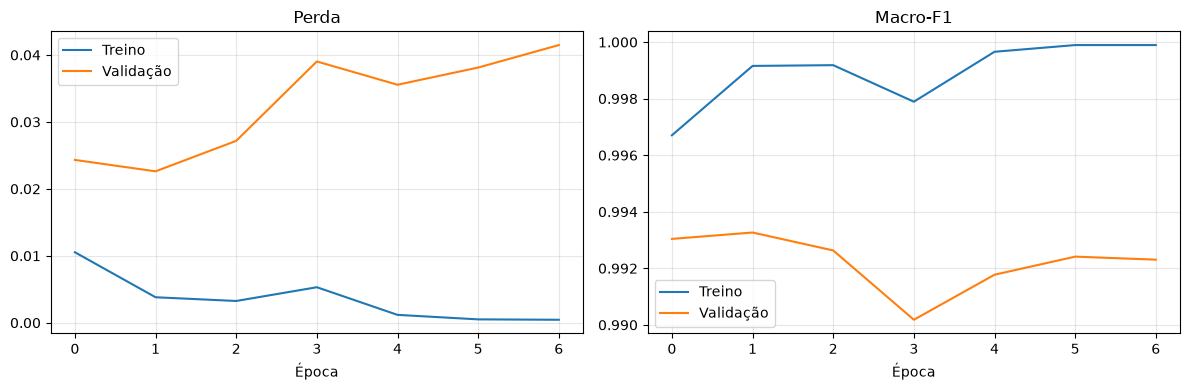

In [10]:
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history["train_loss"], label="Treino")
    plt.plot(history["val_loss"], label="Validação")
    plt.title("Perda")
    plt.xlabel("Época")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(history["train_macro_f1"], label="Treino")
    plt.plot(history["val_macro_f1"], label="Validação")
    plt.title("Macro-F1")
    plt.xlabel("Época")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib não instalado; as métricas continuam disponíveis.")


## 8. Guardar pesos, vectorizador e resultados

Os ficheiros guardados permitem reproduzir a inferência sem voltar a treinar imediatamente o modelo.


In [11]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

np.savez(MODELS_DIR / "dnn_numpy_weights.npz", **dnn.params)
np.savez(MODELS_DIR / "logistic_numpy_weights.npz", W=logistic.W, b=logistic.b)

with open(MODELS_DIR / "dnn_numpy_vectorizer.json", "w", encoding="utf-8") as file:
    json.dump({"vocab": vocab, "idf": idf.tolist()}, file, ensure_ascii=False)

with open(MODELS_DIR / "dnn_numpy_config.json", "w", encoding="utf-8") as file:
    json.dump({
        "seed": SEED,
        "hidden_dims": [256, 128],
        "activation": "elu",
        "lambda_l2": 1e-5,
        "dropout_rate": 0.3,
        "max_features": MAX_FEATURES,
        "threshold": 0.5,
        "label_definition": {"0": "Human", "1": "AI"}
    }, file, indent=2, ensure_ascii=False)

with open(MODELS_DIR / "tarefa2_results.json", "w", encoding="utf-8") as file:
    json.dump(comparison, file, indent=2, ensure_ascii=False)

print("Artefactos guardados em:", MODELS_DIR.resolve())
for path in sorted(MODELS_DIR.iterdir()):
    print(" -", path.name)


Artefactos guardados em: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\modelos_numpy
 - dnn_numpy_config.json
 - dnn_numpy_vectorizer.json
 - dnn_numpy_weights.npz
 - logistic_numpy_weights.npz
 - tarefa2_results.json


## 9. Submissão externa com `dataset_de _entrada.csv`

O ficheiro do professor não contém labels. É utilizado exclusivamente para inferência. As labels submetidas são exactamente `Human` e `AI`.


In [12]:
if not TEACHER_INPUTS.exists():
    print(f"{TEACHER_INPUTS.resolve()} não encontrado; a submissão não foi gerada.")
else:
    with open(TEACHER_INPUTS, "r", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file, delimiter=";")
        rows = list(reader)
        columns = reader.fieldnames or []

    if len(rows) != 100:
        raise ValueError(f"Esperavam-se 100 inputs; encontrados {len(rows)}")
    if columns != ["ID", "Text"]:
        raise ValueError(f"Colunas inesperadas: {columns}")

    teacher_ids = [row["ID"] for row in rows]
    teacher_texts = [row["Text"] or "" for row in rows]
    if len(set(teacher_ids)) != 100:
        raise ValueError("Existem IDs duplicados nos inputs externos.")
    if any(not text.strip() for text in teacher_texts):
        raise ValueError("Existem textos vazios nos inputs externos.")

    # A DNN é o modelo oficial s1 desta versão do notebook.
    X_teacher = texts_to_tfidf_direct(teacher_texts, vocab, idf).T
    teacher_predictions = dnn.predict(X_teacher)
    teacher_labels = np.where(teacher_predictions == 1, "AI", "Human")

    submission_name = f"submissao1-grupo{GROUP_NUMBER}-s{SUBMISSION_NUMBER}.csv"
    submission_path = SUBMISSION_DIR / submission_name

    with open(submission_path, "w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file, delimiter=";")
        writer.writerow(["ID", "Text", "output"])
        writer.writerows(zip(teacher_ids, teacher_texts, teacher_labels))

    print("Submissão NumPy criada:", submission_path.resolve())
    print("Distribuição:", dict(Counter(teacher_labels)))


Submissão NumPy criada: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1\submissao1-grupo7-s2.csv
Distribuição: {np.str_('AI'): 86, np.str_('Human'): 14}


In [13]:
# 10. Validação final do CSV de submissão
if TEACHER_INPUTS.exists():
    with open(submission_path, "r", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file, delimiter=";")
        saved_rows = list(reader)
        saved_columns = reader.fieldnames or []

    assert len(saved_rows) == 100
    assert saved_columns == ["ID", "Text", "output"]
    assert len({row["ID"] for row in saved_rows}) == 100
    assert all(row["output"] in {"Human", "AI"} for row in saved_rows)

    print("FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO")
    print("Ficheiro:", submission_path.resolve())
    print("Linhas:", len(saved_rows))
    print("Labels:", dict(Counter(row["output"] for row in saved_rows)))


FICHEIRO DE SUBMISSÃO VALIDADO COM SUCESSO
Ficheiro: C:\Users\donex\OneDrive\Desktop\MEI\Módulos\Aprendizagem profunda\Moodle\aulas\class3-notebooks\Tarefa_1\Submissao1\submissao1-grupo7-s2.csv
Linhas: 100
Labels: {'AI': 86, 'Human': 14}


## Checklist final da Tarefa 2

- [x] DNN implementada com NumPy.
- [x] Regressão logística baseline implementada com NumPy.
- [x] TF-IDF implementado de raiz.
- [x] Split estratificado.
- [x] Vocabulário/IDF ajustados apenas no treino.
- [x] ELU e inicialização He.
- [x] Dropout e regularização L2.
- [x] Adam implementado de raiz.
- [x] Learning-rate decay e early stopping.
- [x] Avaliação com Accuracy, Precision, Recall, F1 e Macro-F1.
- [x] Matriz de confusão.
- [x] Comparação entre baseline e DNN.
- [x] Pesos e configurações guardados.
- [x] Inferência externa preparada para `dataset3_inputs.csv`.
- [x] Labels de submissão estritamente `Human` ou `AI`.

A pasta `Submissao1` contém o CSV da DNN NumPy (`s1`). O segundo CSV oficial deverá ser produzido pelo segundo melhor modelo do grupo, por exemplo a BiLSTM PyTorch.
